<a href="https://colab.research.google.com/github/garcialvarez/HAR/blob/main/04_cnn1d_dominio_tiempo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 04 — CNN 1D sobre la señal cruda (familia A: dominio del tiempo)

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/garcialvarez/HAR/blob/main/04_cnn1d_dominio_tiempo.ipynb)

**Entrega 2 — Notebook 4 de 7.** Primera arquitectura de *deep learning*: una red convolucional 1D que
recibe la ventana tal cual (128 pasos × canales) y aprende sus propios filtros, sin las 561 features
manuales. Es la primera de las **dos familias de modelos** que se comparan (retroalimentación de la
Entrega 1): *serie en el tiempo* (notebooks 04 y 05) frente a *tiempo-frecuencia* (notebook 06).

**Experimentos (iteraciones):**

| Id | Entrada | Qué se prueba |
|---|---|---|
| A1 | 9 canales crudos | referencia |
| A2 | + 3 magnitudes (12 canales) | invariancia a la orientación del teléfono |
| A3 | + 3 de velocidad integrada y corregida (15 canales) | ¿sirve la integración numérica? (ver notebook 02, sección 4) |
| A4 | A2 + aumento de datos (escala y ruido aleatorios) | ¿mejora la generalización a sujetos nuevos? |

**Protocolo.** Validación por sujeto dentro del train oficial (≈16 sujetos para entrenar, ≈5 para
validar y parar el entrenamiento), normalizador ajustado solo con entrenamiento y evaluación final en los
9 sujetos del test oficial. Cada experimento se repite con **3 semillas** y se reporta media ± desviación,
porque con tan pocos sujetos una sola ejecución no permite distinguir un efecto real del azar.

**Entradas:** dataset UCI HAR. **Salidas:** métricas en este notebook y en `results/` (local, no versionado).

In [1]:
# --- Arranque (Colab o local): clona el repositorio si hace falta y entra en él ---
import os, subprocess

REPO_URL = "https://github.com/garcialvarez/HAR.git"

if not os.path.exists("src/data_loader.py"):      # en Colab: cwd = /content
    if not os.path.isdir("HAR"):
        subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
    os.chdir("HAR")

print("Directorio de trabajo:", os.getcwd())

Directorio de trabajo: /content/HAR


In [2]:
# Instala las dependencias (en Colab casi todas ya vienen instaladas).
%pip install -q -r requirements.txt

In [3]:
# Descarga y descomprime el UCI HAR Dataset (si no está ya en data/raw/).
import sys
sys.path.append("src")

from data_loader import download_dataset
download_dataset()

Descargando dataset (intento 1/3)...
Descargado: 61.0 MB


PosixPath('/content/HAR/data/raw/UCI_HAR_Dataset')

In [4]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from data_loader import load_raw_signals
from evaluation import plot_confusion_matrix, plot_history
from preprocessing import CLASS_NAMES, encode_labels
from training import evaluate_keras, fit_keras, prepare_time_inputs

pd.set_option("display.width", 130)
SEEDS = (42, 43, 44)

X_tr_raw, y_tr_s, s_tr = load_raw_signals("train")
X_te_raw, y_te_s, _ = load_raw_signals("test")
y_tr, y_te = encode_labels(y_tr_s), encode_labels(y_te_s)
s_tr = s_tr.values
print("train:", X_tr_raw.shape, "| test:", X_te_raw.shape, "| GPU:", bool(tf.config.list_physical_devices("GPU")))

train: (7352, 128, 9) | test: (2947, 128, 9) | GPU: False


## 1. Arquitectura

```
Entrada (128, C)
 → [Conv1D(64, k=5) → BatchNorm → ReLU] × 2 → MaxPool(2) → Dropout(0.3)
 → Conv1D(128, k=3) → BatchNorm → ReLU
 → GlobalAveragePooling1D → Dense(64) → Dropout(0.5) → Dense(6, softmax)
```

La convolución detecta patrones locales (un pico de aceleración, un cambio de orientación) con los
mismos filtros en cualquier instante de la ventana; `GlobalAveragePooling` resume el resultado sin
depender de dónde ocurrió. Con ≈ 59 mil parámetros es una red pequeña, apta para un teléfono.

**Aumento de datos (solo A4):** cada ventana se multiplica por un factor aleatorio por canal
(~N(1, 0.15)) y se le suma ruido gaussiano (σ = 0.2 sobre datos estandarizados). Ambos solo actúan
durante el entrenamiento.

In [5]:
@keras.utils.register_keras_serializable(package="har")
class RandomScale(layers.Layer):
    """Multiplica cada canal por un factor ~N(1, sigma). Solo actúa en entrenamiento."""

    def __init__(self, sigma=0.15, **kwargs):
        super().__init__(**kwargs)
        self.sigma = sigma

    def call(self, x, training=None):
        if not training:
            return x
        return x * tf.random.normal((tf.shape(x)[0], 1, tf.shape(x)[2]), 1.0, self.sigma)

    def get_config(self):
        return {**super().get_config(), "sigma": self.sigma}


def build_cnn1d(input_shape, augment=False):
    inp = keras.Input(input_shape)
    x = inp
    if augment:
        x = RandomScale(0.15)(x)
        x = layers.GaussianNoise(0.2)(x)
    for _ in range(2):
        x = layers.Conv1D(64, 5, padding="same")(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
    x = layers.MaxPooling1D(2)(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Conv1D(128, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    return keras.Model(inp, layers.Dense(6, activation="softmax")(x), name="cnn1d")


build_cnn1d((128, 12)).summary()

Model: "cnn1d"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 12)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 128, 64)        │         3,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 128, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 128, 64)        │        20,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 128, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 64, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 64, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 64, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 58,822 (229.77 KB)

 Trainable params: 58,310 (227.77 KB)

 Non-trainable params: 512 (2.00 KB)

## 2. Entrenamiento de los experimentos

Cada entrenamiento usa Adam (lr = 1e-3), `EarlyStopping` sobre la pérdida de validación (paciencia 8,
restaura los mejores pesos), `ReduceLROnPlateau` y un máximo de 40 épocas.

In [6]:
EXPERIMENTOS = {          # id: (variante de canales, aumento de datos)
    "A1": ("raw", False),
    "A2": ("mag", False),
    "A3": ("mag_vel", False),
    "A4": ("mag", True),
}

runs = {}                 # id -> lista de dicts (uno por semilla)
histories = {}            # id -> History de la primera semilla (para graficar)
t_total = time.perf_counter()

for exp, (variante, aug) in EXPERIMENTOS.items():
    d = prepare_time_inputs(X_tr_raw, X_te_raw, s_tr, variante)
    ytr, yva = y_tr[d["tr"]], y_tr[d["va"]]
    runs[exp] = []
    for seed in SEEDS:
        keras.utils.set_random_seed(seed)
        model = build_cnn1d(d["Xtr"].shape[1:], augment=aug)
        hist, seg = fit_keras(model, d["Xtr"], ytr, d["Xva"], yva, epochs=40)
        mejor = int(np.argmin(hist.history["val_loss"]))
        res = evaluate_keras(f"04_{exp}_s{seed}", "tiempo_cnn1d", model, d["Xte"], y_te, CLASS_NAMES, seg,
                             notes=f"{exp}: canales={variante}, aumento={aug}, semilla={seed}")
        res.update(val_loss=hist.history["val_loss"][mejor], val_acc=hist.history["val_accuracy"][mejor],
                   epocas=len(hist.history["loss"]))
        runs[exp].append(res)
        if seed == SEEDS[0]:
            histories[exp] = hist
print(f"\nTiempo total: {(time.perf_counter() - t_total) / 60:.1f} min")

[04_A1_s42] accuracy=0.9023  F1 macro=0.9023  latencia=2.21 ms/ventana
[04_A1_s43] accuracy=0.9345  F1 macro=0.9341  latencia=1.37 ms/ventana
[04_A1_s44] accuracy=0.9410  F1 macro=0.9413  latencia=2.14 ms/ventana
[04_A2_s42] accuracy=0.9155  F1 macro=0.9162  latencia=1.33 ms/ventana
[04_A2_s43] accuracy=0.9284  F1 macro=0.9292  latencia=1.36 ms/ventana
[04_A2_s44] accuracy=0.9148  F1 macro=0.9148  latencia=2.16 ms/ventana
[04_A3_s42] accuracy=0.9074  F1 macro=0.9079  latencia=1.34 ms/ventana
[04_A3_s43] accuracy=0.9281  F1 macro=0.9285  latencia=1.36 ms/ventana
[04_A3_s44] accuracy=0.9209  F1 macro=0.9220  latencia=1.40 ms/ventana
[04_A4_s42] accuracy=0.9179  F1 macro=0.9175  latencia=1.40 ms/ventana
[04_A4_s43] accuracy=0.9104  F1 macro=0.9101  latencia=2.20 ms/ventana
[04_A4_s44] accuracy=0.9332  F1 macro=0.9342  latencia=1.43 ms/ventana

Tiempo total: 24.5 min


## 3. Resultados por experimento

Media ± desviación sobre las 3 semillas. `val acc` es la accuracy en los ≈ 5 sujetos de validación;
`test acc`, la del test oficial (9 sujetos distintos).

In [7]:
def ms(exp, clave):
    v = np.array([r[clave] for r in runs[exp]], dtype=float)
    return v.mean(), v.std()


filas = {}
for exp in EXPERIMENTOS:
    fila = {}
    for etiqueta, clave in [("val acc", "val_acc"), ("test acc", "accuracy"), ("F1 macro test", "f1_macro")]:
        m, s = ms(exp, clave)
        fila[etiqueta] = f"{m:.4f} ± {s:.4f}"
    fila["parámetros"] = runs[exp][0]["n_params"]
    fila["latencia (ms/ventana)"] = round(ms(exp, "latency_single_ms")[0], 3)
    fila["épocas (media)"] = round(ms(exp, "epocas")[0], 1)
    fila["entrenamiento (s)"] = round(ms(exp, "train_time_s")[0], 1)
    filas[exp] = fila
resumen = pd.DataFrame(filas).T
display(resumen)

# Por semilla, para ver la dispersión
display(pd.DataFrame({exp: [round(r["accuracy"], 4) for r in runs[exp]] for exp in EXPERIMENTOS},
                     index=[f"semilla {s}" for s in SEEDS]).T)

,val acc,test acc,F1 macro test,parámetros,latencia (ms/ventana),épocas (media),entrenamiento (s)
A1,0.9695 ± 0.0093,0.9259 ± 0.0169,0.9259 ± 0.0170,57862,1.906,17.7,144.4
A2,0.9722 ± 0.0020,0.9196 ± 0.0062,0.9201 ± 0.0065,58822,1.616,13.0,103.2
A3,0.9785 ± 0.0011,0.9188 ± 0.0086,0.9194 ± 0.0086,59782,1.368,12.7,103.8
A4,0.9808 ± 0.0056,0.9205 ± 0.0095,0.9206 ± 0.0101,58822,1.678,15.7,125.1


,semilla 42,semilla 43,semilla 44
A1,0.9023,0.9345,0.9410
A2,0.9155,0.9284,0.9148
A3,0.9074,0.9281,0.9209
A4,0.9179,0.9104,0.9332


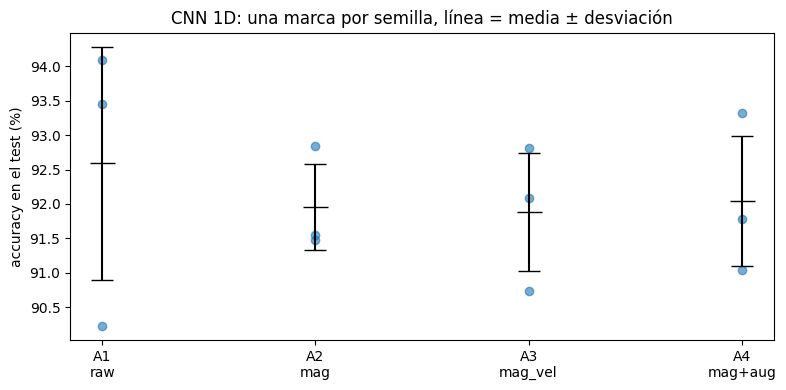

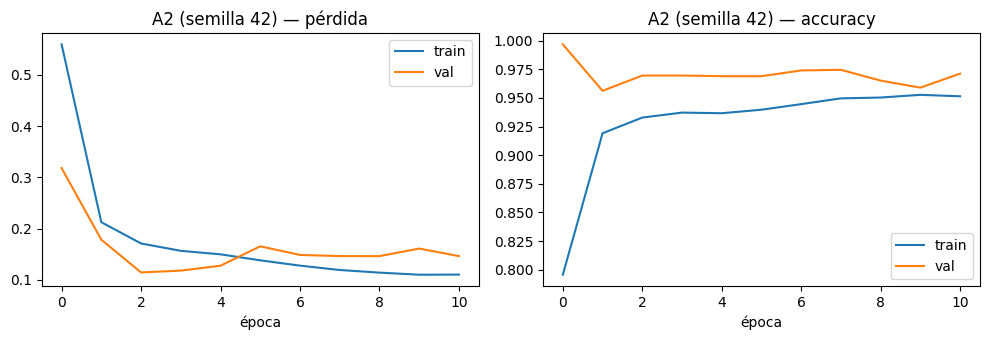

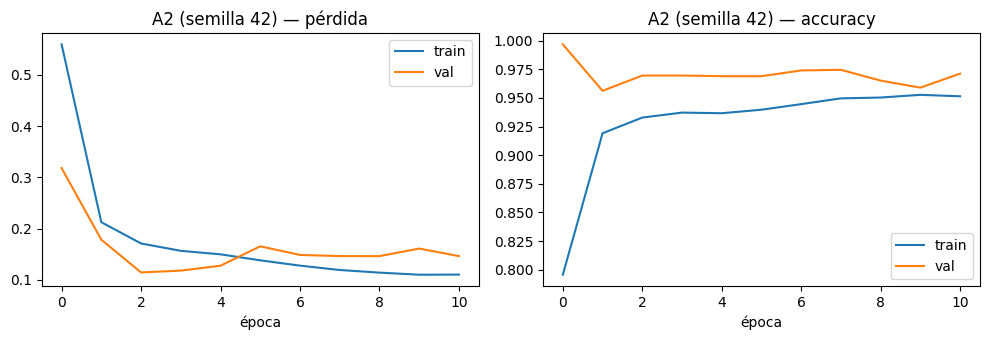

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
for k, exp in enumerate(EXPERIMENTOS):
    accs = [100 * r["accuracy"] for r in runs[exp]]
    ax.scatter([k] * len(accs), accs, color="C0", alpha=0.6, zorder=3)
    ax.errorbar(k, np.mean(accs), yerr=np.std(accs), fmt="_", color="k", capsize=8, markersize=18, zorder=4)
ax.set_xticks(range(len(EXPERIMENTOS)), [f"{e}\n{EXPERIMENTOS[e][0]}" + ("+aug" if EXPERIMENTOS[e][1] else "")
                                         for e in EXPERIMENTOS])
ax.set_ylabel("accuracy en el test (%)")
ax.set_title("CNN 1D: una marca por semilla, línea = media ± desviación")
fig.tight_layout()
plt.show()

plot_history(histories["A2"], title="A2 (semilla 42)", save_name="04_curvas_A2.png")

## 4. Finalista de la familia y errores por clase

El finalista se elige por la **menor pérdida de validación media** (no por el test). Se suman las matrices
de confusión de las 3 semillas.

Finalista de la familia CNN 1D: A4 (pérdida de validación media = 0.0675)


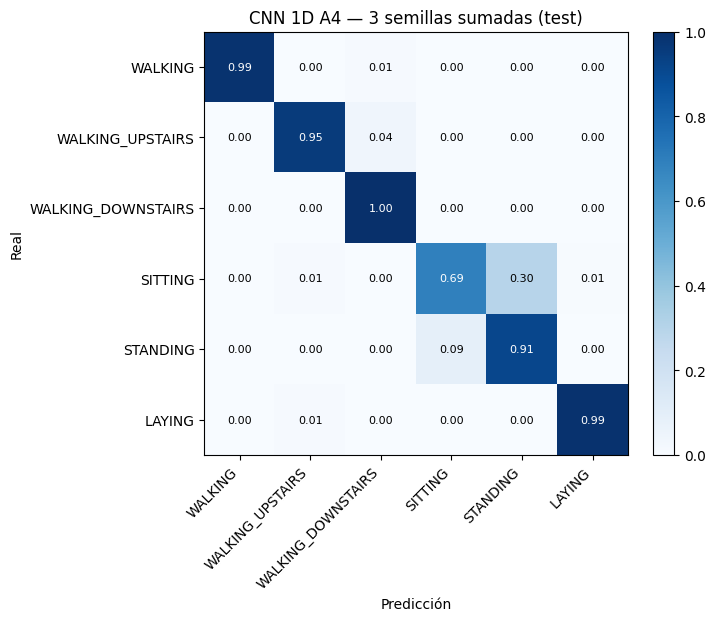

,tasa de falsos negativos
WALKING,0.012
WALKING_UPSTAIRS,0.045
WALKING_DOWNSTAIRS,0.002
SITTING,0.312
STANDING,0.090
LAYING,0.010


In [9]:
finalista = min(EXPERIMENTOS, key=lambda e: ms(e, "val_loss")[0])
print(f"Finalista de la familia CNN 1D: {finalista} (pérdida de validación media = {ms(finalista, 'val_loss')[0]:.4f})")

cm = np.sum([r["confusion_matrix"] for r in runs[finalista]], axis=0)
plot_confusion_matrix(cm, CLASS_NAMES, title=f"CNN 1D {finalista} — 3 semillas sumadas (test)",
                      save_name="04_confusion_finalista.png")

fn = pd.DataFrame({c: np.mean([r["false_negative_rate"][c] for r in runs[finalista]]) for c in CLASS_NAMES},
                  index=["tasa de falsos negativos"]).T
display(fn.round(3))

## Conclusiones

In [10]:
base = ms("A1", "accuracy")
print("Efecto de cada cambio sobre A1 (accuracy en test, media ± desviación entre semillas):")
for exp in ("A2", "A3", "A4"):
    m, s = ms(exp, "accuracy")
    dif = 100 * (m - base[0])
    ruido = 100 * max(s, base[1])
    veredicto = "dentro del ruido entre semillas" if abs(dif) <= ruido else ("mejora" if dif > 0 else "empeora")
    print(f"  {exp}: {100 * m:.2f} % ({dif:+.2f} puntos; ruido ≈ {ruido:.2f}) → {veredicto}")

conf = np.array(cm)
i, j = CLASS_NAMES.index("SITTING"), CLASS_NAMES.index("STANDING")
errores = conf.sum() - np.trace(conf)
print(f"- Del total de errores del finalista, {100 * (conf[i, j] + conf[j, i]) / errores:.0f} % son SITTING↔STANDING.")
va, te = ms(finalista, "val_acc")[0], ms(finalista, "accuracy")[0]
print(f"- Brecha de generalización: {100 * va:.1f} % en los sujetos de validación frente a {100 * te:.1f} % en los del test.")
print("  La red aprende bien a los sujetos vistos y generaliza peor a sujetos nuevos: ese es el cuello de botella.")

Efecto de cada cambio sobre A1 (accuracy en test, media ± desviación entre semillas):
  A2: 91.96 % (-0.63 puntos; ruido ≈ 1.69) → dentro del ruido entre semillas
  A3: 91.88 % (-0.71 puntos; ruido ≈ 1.69) → dentro del ruido entre semillas
  A4: 92.05 % (-0.54 puntos; ruido ≈ 1.69) → dentro del ruido entre semillas
- Del total de errores del finalista, 82 % son SITTING↔STANDING.
- Brecha de generalización: 98.1 % en los sujetos de validación frente a 92.0 % en los del test.
  La red aprende bien a los sujetos vistos y generaliza peor a sujetos nuevos: ese es el cuello de botella.


**Lectura.** La CNN 1D alcanza una accuracy claramente inferior a la del SVM sobre las 561 features
(notebook 03) cuando se evalúa en sujetos nuevos. El error se concentra en las posturas estáticas
(*sentado* vs *de pie*), cuya única diferencia es una ligera inclinación del tronco/teléfono que varía de
persona a persona. Ninguno de los cambios probados (canales extra, velocidad integrada, aumento de datos)
mejora a la referencia A1; las diferencias son del orden del ruido entre semillas o, en A3 y A4, algo peores.
Una posible explicación de A4 (hipótesis, no comprobada aquí): escalar aleatoriamente los canales de
`total_acc` también distorsiona la gravedad, que es justo la pista que separa *sentado* de *de pie*.

Siguiente: [`05_recurrentes_lstm.ipynb`](05_recurrentes_lstm.ipynb) — redes recurrentes (LSTM y DRNN),
la arquitectura del artículo de referencia, también en el dominio del tiempo.